# Practical Assignment 5 – Ensemble Learning and Performance Evaluation

**Name :- Pushkar Parakh Div:-E Batch:-E1 Roll NO:- 313 PRN :- 202401040313**

**GITHUB REPO** :- https://github.com/pushkarparakh/AIML-313/blob/main/CA/Practical%205/Practical_5_Ensemble_Learning.ipynb

## Aim
Implement Stacking, AdaBoost and Voting ensembles, then compare them with individual classifiers using classification metrics.

**Dataset:** Wisconsin Diagnostic Breast Cancer dataset. It contains measurements computed from digitized images of breast mass samples. The target is whether a sample is malignant or benign.

## 1. Import libraries and load the dataset

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import StackingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

DATA_PATH = Path("data") / "breast_cancer_wisconsin.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("Run this notebook from the Practical 5 folder so the data folder is available.")
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
display(df.head())
display(df["diagnosis"].value_counts().rename("sample_count").to_frame())

Dataset shape: (569, 32)
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


,sample_count
diagnosis,
benign,357
malignant,212


## 2. Prepare features and target

The dataset's diagnosis is converted to a binary target where **1 = malignant** and **0 = benign**. This makes precision and recall focus on detecting malignant cases. The original `target` and text `diagnosis` columns are excluded from the features.

In [5]:
feature_cols = [c for c in df.columns if c not in ["target", "diagnosis"]]
X = df[feature_cols].copy()
y = (df["diagnosis"] == "malignant").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Malignant cases in full dataset:", int(y.sum()))

Training samples: 455
Testing samples: 114
Malignant cases in full dataset: 212


## 3. Define the base classifiers

Logistic Regression and SVM use standardization because they are sensitive to feature scales. The Decision Tree does not require scaling. These three different classifiers are used as individual models and as the base estimators for the ensembles.

In [6]:
base_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, random_state=42))
    ])
}

for name, model in base_models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Logistic Regression trained
Decision Tree trained
SVM trained


## 4. Implement the ensemble models

### 4.1 Stacking Classifier

Stacking trains a meta-classifier using cross-validated predictions from the base classifiers. Logistic Regression is used as the final estimator to combine their outputs.

In [7]:
stacking_model = StackingClassifier(
    estimators=[
        ("lr", Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=5000, random_state=42))
        ])),
        ("tree", DecisionTreeClassifier(max_depth=5, random_state=42)),
        ("svm", Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(kernel="rbf", probability=True, random_state=42))
        ]))
    ],
    final_estimator=LogisticRegression(max_iter=5000, random_state=42),
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)
stacking_model.fit(X_train, y_train)
print("Stacking ensemble trained.")

Stacking ensemble trained.


### 4.2 AdaBoost Classifier

AdaBoost builds a sequence of weak learners. Each new learner gives more attention to samples that earlier learners classified incorrectly. A shallow Decision Tree (decision stump) is selected as the weak learner.

In [8]:
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)
ada_model.fit(X_train, y_train)
print("AdaBoost ensemble trained.")

AdaBoost ensemble trained.


### 4.3 Voting Classifier

Soft voting combines the predicted class probabilities of the base classifiers and selects the class with the highest average probability. All three base models support probability prediction.

In [9]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=5000, random_state=42))
        ])),
        ("tree", DecisionTreeClassifier(max_depth=5, random_state=42)),
        ("svm", Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(kernel="rbf", probability=True, random_state=42))
        ]))
    ],
    voting="soft",
    n_jobs=-1
)
voting_model.fit(X_train, y_train)
print("Soft voting ensemble trained.")

Soft voting ensemble trained.


## 5. Evaluate base models and ensemble models

The positive class is malignant (1). Precision indicates how many predicted malignant cases were actually malignant; recall indicates how many actual malignant cases were detected. F1-score balances precision and recall. ROC-AUC measures ranking performance across thresholds.

In [10]:
all_models = {**base_models,
              "Stacking": stacking_model,
              "AdaBoost": ada_model,
              "Soft Voting": voting_model}

results = []
predictions = {}

for name, model in all_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("F1-score", ascending=False)
display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Stacking,0.9825,1.0000,0.9524,0.9756,0.9964
SVM,0.9737,1.0000,0.9286,0.9630,0.9947
AdaBoost,0.9737,1.0000,0.9286,0.9630,0.9858
Logistic Regression,0.9649,0.9750,0.9286,0.9512,0.9960
Soft Voting,0.9649,1.0000,0.9048,0.9500,0.9960
Decision Tree,0.9211,0.9459,0.8333,0.8861,0.9448


## 6. Compare the models

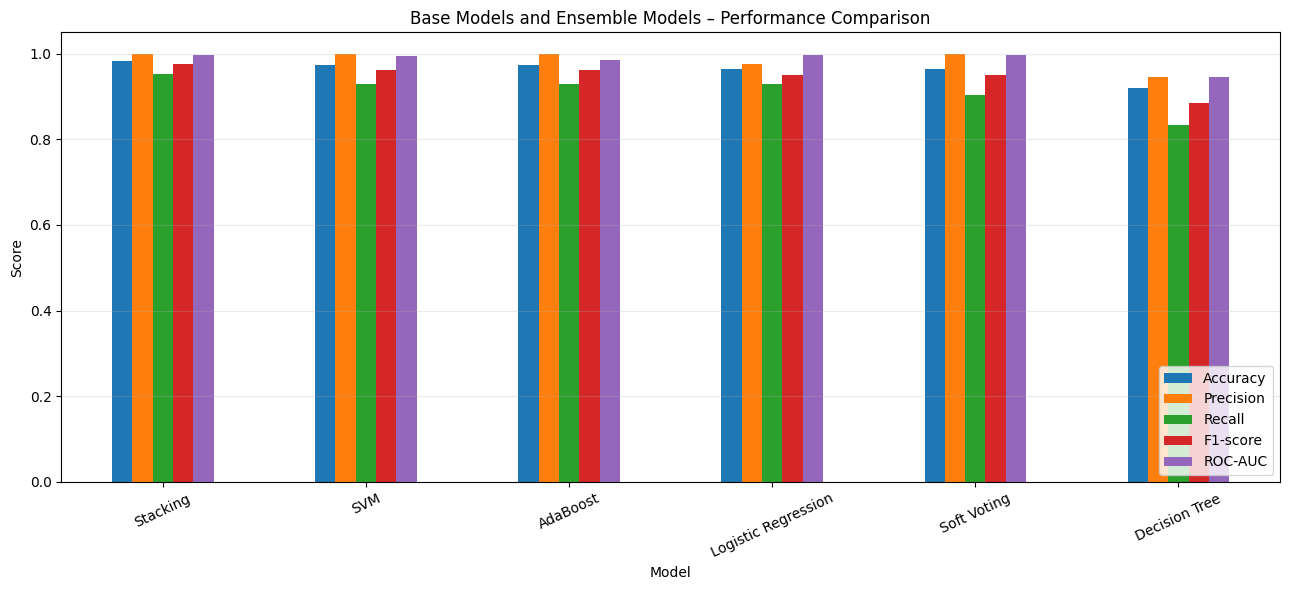

In [11]:
ax = results_df[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(13, 6), ylim=(0, 1.05)
)
ax.set_title("Base Models and Ensemble Models – Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Confusion matrices and classification report

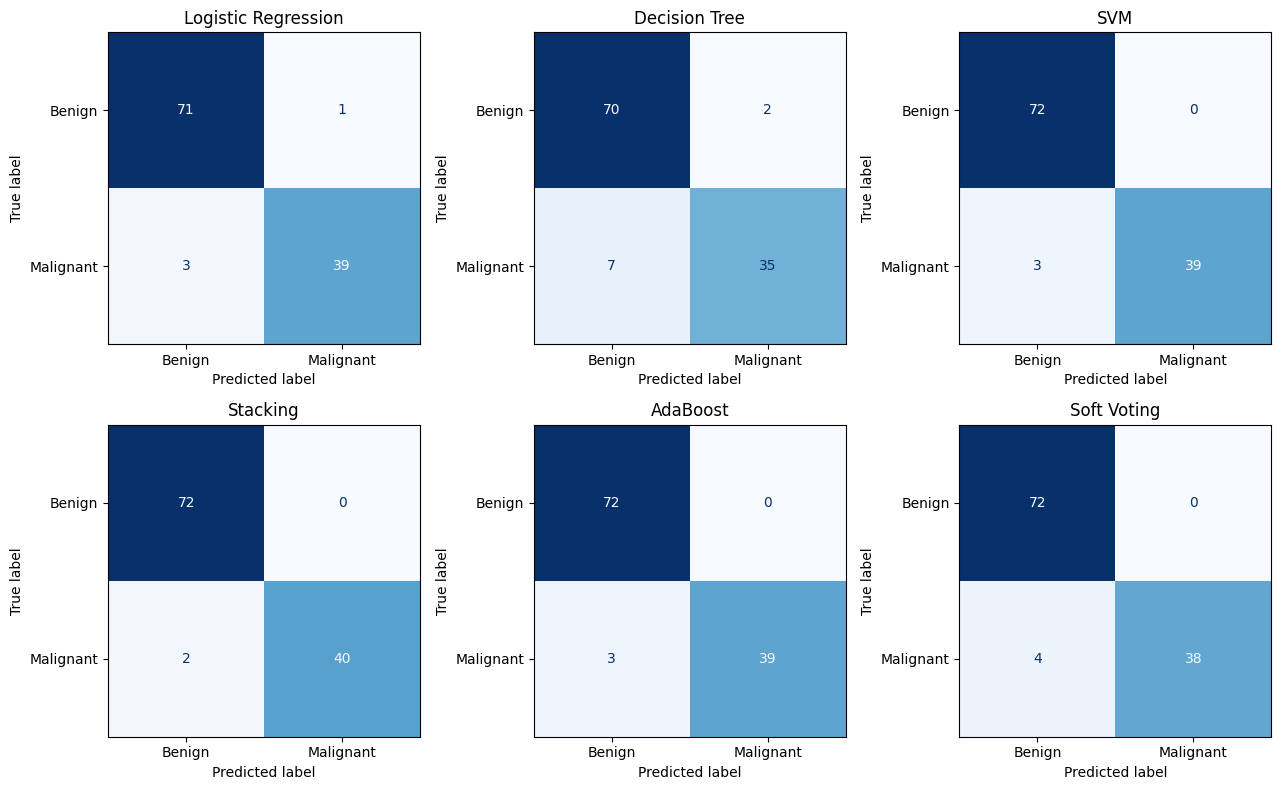

Best model by F1-score: Stacking

Classification report:
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99        72
   Malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, y_pred) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)
for ax in axes.flat[len(predictions):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

best_model_name = results_df["F1-score"].idxmax()
print("Best model by F1-score:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test, predictions[best_model_name],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

## 8. Findings and when to use each method

In [13]:
# Print the measured result for each model so the conclusion is based on this run.
for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]:
    best_name = results_df[metric].idxmax()
    print(f"Highest {metric}: {best_name} ({results_df.loc[best_name, metric]:.4f})")

Highest Accuracy: Stacking (0.9825)
Highest Precision: Stacking (1.0000)
Highest Recall: Stacking (0.9524)
Highest F1-score: Stacking (0.9756)
Highest ROC-AUC: Stacking (0.9964)


### Interpretation

- **Stacking:** Useful when different base classifiers make complementary errors. A meta-classifier learns how to combine their predictions, but training is more computationally expensive.
- **AdaBoost:** Useful when a sequence of weak learners can improve performance by focusing on previously misclassified observations. It can be sensitive to noisy data and outliers.
- **Voting:** A simple way to combine several reasonably strong and diverse models. It is easy to implement and does not require a separate meta-classifier.
- **Base classifiers:** They provide a useful reference. An ensemble is not automatically better; its test metrics should be compared with the individual models.

For this dataset, use the comparison table and confusion matrices to decide which model best balances detecting malignant cases and avoiding false alarms. In a medical setting, recall for malignant cases is particularly important, but model output must not be treated as a clinical diagnosis.

## 9. Conclusion and possible improvements

The three ensemble approaches were implemented and evaluated alongside Logistic Regression, Decision Tree and SVM. Accuracy, precision, recall, F1-score and ROC-AUC were used for comparison, while confusion matrices showed the types of prediction errors.

Further improvements could include repeated stratified cross-validation, hyperparameter tuning, testing other base learners, calibration of predicted probabilities and evaluating the models on an independent external dataset. Since the dataset relates to medical diagnosis, privacy, class imbalance, false negatives and the need for expert clinical validation should also be considered.

## Dataset source

Wisconsin Diagnostic Breast Cancer dataset, distributed with scikit-learn and originally available through the UCI Machine Learning Repository.

- UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- scikit-learn dataset documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html